<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P5_implementation_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## RNN Using TensorFlow's High-Level API

Previously, we implemented the RNN calculations manually.

Now TensorFlow will create and manage the recurrent weights and hidden-state calculations for us using:

`tf.keras.layers.SimpleRNN`

The RNN concept remains the same:

`current input + previous hidden state → new hidden state`

The difference is that we no longer write that calculation ourselves.


In [ ]:
!pip install --q d2l --no-deps

In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l

In [ ]:
class RNN(d2l.Module):
    """RNN implemented using TensorFlow's built-in SimpleRNN."""

    def __init__(self, num_inputs, num_hiddens):
        super().__init__()
        self.save_hyperparameters()

        self.rnn = tf.keras.layers.SimpleRNN(
            num_hiddens,
            return_sequences=True,
            return_state=True
        )

    def forward(self, inputs, H=None):

        # D2L input:
        # (num_steps, batch_size, num_inputs)

        # Keras expects:
        # (batch_size, num_steps, num_inputs)
        inputs = tf.transpose(inputs, (1, 0, 2))

        outputs, H = self.rnn(
            inputs,
            initial_state=H
        )

        # Convert back to D2L format:
        # (num_steps, batch_size, num_hiddens)
        outputs = tf.transpose(outputs, (1, 0, 2))

        return outputs, H

## What Changed in the Concise RNN?

The RNN idea is the same, but TensorFlow now handles the internal calculations for us.

**From scratch, we manually created:**

- `W_xh` — input → hidden weights
- `W_hh` — hidden → hidden weights
- `b_h` — hidden-state bias
- the `tanh` hidden-state update
- the loop through time steps

**With TensorFlow:**

`tf.keras.layers.SimpleRNN(...)`

automatically creates the weights, updates the hidden state, and processes the sequence.

We still keep the same overall flow:

`input → RNN → hidden state → output layer → next-character prediction`

> **Key idea:** `SimpleRNN` replaces the manual RNN calculations, not the RNN concept.

In [ ]:
class RNNLM(d2l.RNNLMScratch):
    """RNN language model using TensorFlow's high-level RNN."""

    def init_params(self):

        # Convert each hidden state into scores for
        # every possible character in the vocabulary.
        self.linear = tf.keras.layers.Dense(self.vocab_size)

    def output_layer(self, hiddens):

        # Apply the Dense layer to every hidden state.
        outputs = self.linear(hiddens)

        # Rearrange dimensions from:
        # (num_steps, batch_size, vocab_size)
        #
        # to:
        # (batch_size, num_steps, vocab_size)
        return tf.transpose(outputs, (1, 0, 2))

### What Does the Dense Layer Do?

If the RNN hidden state contains 32 values and the vocabulary contains 28 characters:

`32 hidden values → Dense layer → 28 character scores`

So the model can predict which character is most likely to come next.

The complete high-level model is therefore:

`one-hot character → SimpleRNN → hidden state → Dense layer → next-character scores`

## Training the High-Level RNN

The training task is unchanged:

`input character sequence → predict the next character at each time step`

The difference is that TensorFlow now manages the RNN's internal recurrent calculations.

During training:

1. `SimpleRNN` produces the hidden states,
2. the `Dense` layer produces next-character scores,
3. cross-entropy measures the error,
4. backpropagation computes gradients,
5. gradient clipping stabilizes training,
6. the optimizer updates the parameters.

We again monitor **perplexity (PPL)**. Lower perplexity means better next-character prediction.

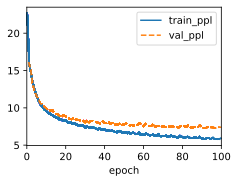

In [ ]:
# Load The Time Machine dataset
data = d2l.TimeMachine(batch_size=1024, num_steps=32)

with d2l.try_gpu():

    # Create the high-level TensorFlow RNN
    rnn = RNN(
        num_inputs=len(data.vocab),
        num_hiddens=32
    )

    # Create the RNN language model
    model = RNNLM(
        rnn,
        vocab_size=len(data.vocab),
        lr=1.0
    )

# Define cross-entropy loss
cross_entropy = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

# Keep compatibility with the earlier D2L training_step
model.loss = lambda prediction, target: cross_entropy(
    target,
    prediction
)

# Train the model
trainer = d2l.Trainer(
    max_epochs=100,
    gradient_clip_val=1.0
)

trainer.fit(model, data)

### Interpreting the Training Result

During training, we monitor **perplexity (PPL)**.

A decreasing perplexity means that the model is assigning higher probability to the correct next characters.

Therefore:

`high perplexity → poor next-character prediction`

`lower perplexity → better next-character prediction`

The important point is that the high-level TensorFlow RNN should achieve performance similar to the scratch implementation, while requiring much less code.

> **Key idea:** The learning task has not changed. TensorFlow's `SimpleRNN` simply performs the recurrent calculations more conveniently and efficiently.

In [ ]:
# Generate 20 characters after the prefix "it has".
model.predict('it has', 20, data.vocab)

'it has there and the the t'